title: "Equity Portfolio APT Analysis"
---

## Introduction

This report analyses the risk-return characteristics of three equities (Apple (AAPL), Amazon (AMZN), and General Electric (GE)) using the provided historical price data in 'Problem set data.xls'. The dataset contains monthly stock prices, a broad market index (S&P 500), and the 1-month T-bill risk-free rate covering the period from January 2019 to October 2024. Stock price series were adjusted for all stock-split events within this period to ensure price continuity and accurate return measurement.

The tasks follow the structure of the problem set and include the computation of monthly returns and the covariance matrix, portfolio expected returns and Sharpe ratios, investor utility maximisation and the Capital Allocation Line (CAL), estimation of single-factor APT betas, and discussion of potential multi-factor extensions.

The entire analysis is conducted within a Jupyter Notebook environment, using Python to perform data manipulation, calculations, and visualisations. 

## Part A: Monthly Returns and Covariance Matrix 

### Adjusted Closing Prices

The analysis begins by importing relevant libraries and reading the `Problem set data.xls` file containing the data. The  `Stock Prices` sheet has been modified to prevent artificial jumps in returns by creating a new column for the adjusted stock prices due to AAPL 4:1 stock split on 28th August 2020 (Apple Inc., 2020), AMZN 20:1 stock split on 3rd June 2022 (Amazon.com, Inc., 2022), and GE 8:1 (reverse) stock split on 2nd August 2021 (General Electric Company, 2021).

We also check for any missing observations and sort the index to ensure the data is in chronological order. The adjusted prices can be seen below. 

In [62]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

xls = pd.ExcelFile("Problem set data.xls")

prices = pd.read_excel(xls, sheet_name="Stock Prices", index_col=7, parse_dates=True)

adj_prices = prices[["AAPL Adjusted Close Price", "AMZN Adjusted Close Price", "GE Adjusted Close Price"]]

# Drop missing rows (if any) and sort dates
adj_prices = adj_prices.dropna(how="all")
adj_prices = adj_prices.sort_index()
adj_prices.round(2).head()

,AAPL Adjusted Close Price,AMZN Adjusted Close Price,GE Adjusted Close Price
Date.1,,,
2019-01-01,41.61,85.94,81.28
2019-02-01,43.29,81.99,83.12
2019-03-01,47.49,89.04,79.92
2019-04-01,50.17,96.33,81.36
2019-05-01,43.77,88.75,75.52


The adjusted closing prices are plotted below using `matplotlib` to illustrate the time-series behaviour of AAPL, AMZN, and GE over the sample period (January 2019 to December 2024). This allows us to observe trends, volatility differences, and relative performance across the three stocks. 

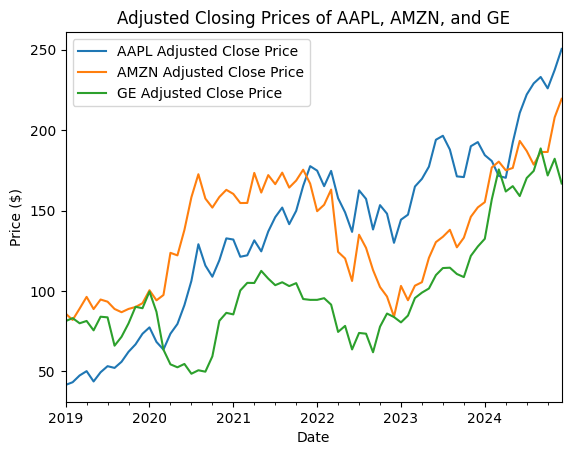

In [42]:
# Plot adjusted closing prices for each stock
adj_prices.plot()
plt.title("Adjusted Closing Prices of AAPL, AMZN, and GE")
plt.xlabel("Date")
plt.ylabel("Price ($)")
plt.legend()
plt.show()

From the plot, we can see that AAPL exhibits the strongest upward trend over the sample, AMZN shows greater medium-term volatility, and GE displays a slower and more irregular growth pattern.

### Stock Monthly Returns

Next, we compute the monthly returns $r_i$ for each stock, using the simple return formula:

$$r_t = \frac{P_{t}-P_{t-1}}{P_{t-1}}=\frac{P_{t}}{P_{t-1}}-1$$

where $P_t$ is the price at month $t$ and $P_{t-1}$ is the price in the previous month. 

In [63]:
# Calculate monthly returns and rename columns to simple tickers (AAPL, AMZN, GE)
monthly_returns = adj_prices.pct_change().dropna().rename(columns={
    "AAPL Adjusted Close Price": "AAPL",
    "AMZN Adjusted Close Price": "AMZN",
    "GE Adjusted Close Price": "GE",
})
monthly_returns.round(5).head()

,AAPL,AMZN,GE
Date.1,,,
2019-02-01,0.04031,-0.04591,0.02264
2019-03-01,0.09703,0.08594,-0.03850
2019-04-01,0.05644,0.08186,0.01802
2019-05-01,-0.12757,-0.07861,-0.07178
2019-06-01,0.13052,0.06679,0.11229


Similarly, we plot the monthly returns of AAPL, AMZN, and GE to examine their volatilities, with the visualisation helping highlight differences in riskiness across the three stocks.

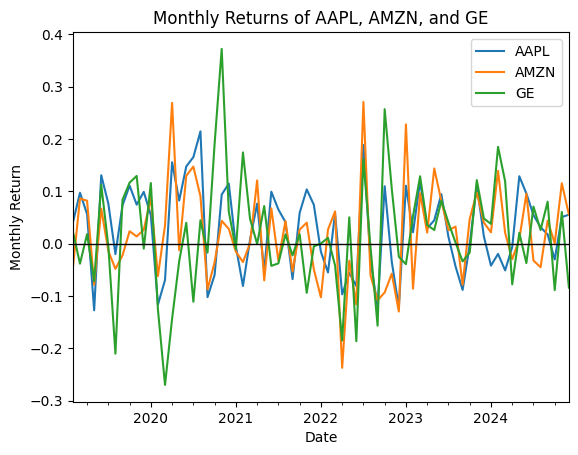

In [44]:
# Plot monthly returns for each stock
monthly_returns.plot()
plt.title("Monthly Returns of AAPL, AMZN, and GE")
plt.xlabel("Date")
plt.ylabel("Monthly Return")
plt.axhline(0, color='black', linewidth=1)
plt.legend()
plt.show()

From the graph, we can see that AAPL and AMZN display similar volatility patterns, with several sharp positive and negative monthly movements, particularly during 2020-2022. GE exhibits even larger swings in some months, reflecting its higher idiosyncratic risk. All three stocks oscillate around zero, as expected for monthly returns, with GE seemingly appearing the most volatile while AAPL appears the most stable. 

### Covariance Matrix

The monthly returns are then used to compute the covariance matrix which is calculated using the sample covariance formula:

$$\operatorname{Cov}(r_i, r_j)=\frac{1}{T-1} \sum_{t=1}^{T} (r_{i,t}-\bar{r_i})(r_{j,t}-\bar{r_j})$$

Here, $\bar{{r}_{i}}$ and $\bar{{r}_{j}}$ denote the sample mean monthly returns of assets $i$ and $j$, respectively. 

The sample covariance matrix indicates how the monthly returns of the three stocks co-move. Higher covariances imply that two stocks tend to move in the same direction more strongly, which reduces diversification benefits within a portfolio.

The covariance matrix rounded to 7 decimal places is shown in the heatmap generated using the `seaborn` library below.

<Axes: >

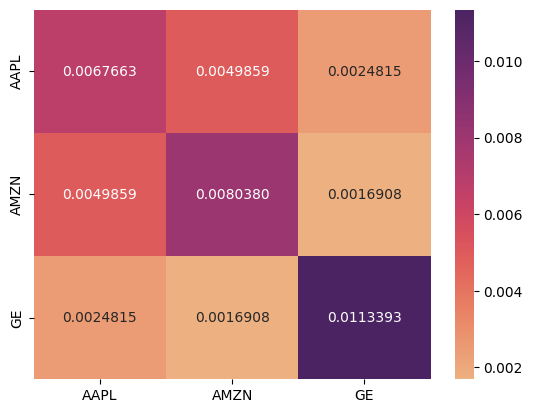

In [45]:
# Calculate the covariance matrix of monthly returns
cov_matrix = monthly_returns.cov()

# Plot the covariance matrix heatmap
sns.heatmap(cov_matrix, annot=True, fmt=".7f", cmap="flare")

The diagonal elements represent each stock’s variance of monthly returns, while the off-diagonal terms show how the stocks move together. 

AAPL and AMZN exhibit the strongest co-movement, with the highest pairwise covariance of 0.004986. This is consistent with both firms operating in technology-driven sectors and being more sensitive to market-wide growth expectations.   

GE has lower covariances with both AAPL (0.002482) and AMZN (0.001691), indicating that it provides slightly better diversification benefits. However, all covariance terms remain positive, so diversification is still limited since none of the stocks move independently of the others. 

In terms of risk, GE has the highest variance (0.011339), making it the most volatile among the three, whereas AAPL has the lowest variance (0.006766), reflecting comparatively more stable monthly returns.

### Method Used

Covariances were computed using the sample covariance formula, implemented in Python via `DataFrame.cov()`. Since, the historical returns represent a sample of possible outcomes rather than the full population of future returns, the unbiased estimator (using denominator $T-1$) is the correct choice. This is consistent with Excel’s COVARIANCE.S function.

### Alternative Methods and Discussion

1. Population Covariance $(T)$
- Pros: Slightly simpler - appropriate if the dataset represents the full population of returns.
- Cons: Underestimates true variability if data is a sample (as in historical monthly data).

2. Log Returns Instead of Simple Returns
- Pros: Additive over time and often closer to normally distributed, which is useful for continuous-time models.
- Cons: Less intuitive economically - small-sample differences negligible, so simple returns are sufficient here.

3. Rolling or Time-Varying Covariance
- Pros: Captures changing market dynamics or volatility clustering, and can be implemented using rolling windows, EWMA, or GARCH models (Johansson, Ogut, Pelger, Schmelzer & Boyd, 2023).
- Cons: More complex, introduces estimation noise which is not required for this static historical analysis.

## Part B: Portfolio Sharpe Ratios 

To compute the historical Sharpe ratios, we first retrieve the risk-free rate from the dataset and convert it into a form suitable for calculating excess returns. Since the 1-month T-bill is a zero-coupon instrument and its yield is assumed to be quoted on an annualised basis, we approximate the corresponding monthly rate by simply dividing the annual yield by 12. This linearised approximation is standard for short-horizon T-bill rates. The conversion is therefore:

$$r_{f}^{monthly}=\frac{r_{f}^{annual}}{12}$$

The risk-free series is then reindexed to match the monthly return dates and forward-filled (`ffill`). This is appropriate because the T-bill rate is constant for an entire month. If a rate is missing for a given return date, the previous month’s rate is the correct value to use. 

In [46]:
rf = pd.read_excel(xls, sheet_name="Risk Free Rate", index_col=0, parse_dates=True).dropna()

# Extract the risk-free rate column and convert from percent to decimal 
rf_annual_pct = rf.iloc[:, 0]
rf_annual = rf_annual_pct / 100

# Approximate monthly risk-free rate from annual rate
rf_monthly = rf_annual / 12

# Reindex risk-free rates to match monthly returns dates and forward-fill missing values (if any)
rf_aligned = rf_monthly.reindex(monthly_returns.index).ffill()
rf_aligned.round(7).head()

Date.1
2019-02-01    0.002025
2019-03-01    0.002042
2019-04-01    0.002025
2019-05-01    0.002000
2019-06-01    0.001850
Name: Return on the T bill (in %), dtype: float64

### Portfolio Monthly Returns

Next, we define the portfolio weights for the three portfolios A, B, and C as follows:

In [47]:
weights = {
    "A": np.array([1/3, 1/3, 1/3]),
    "B": np.array([0.4, 0.4, 0.2]),
    "C": np.array([0.25, 0.25, 0.5]),
}
weights

{'A': array([0.33333333, 0.33333333, 0.33333333]),
 'B': array([0.4, 0.4, 0.2]),
 'C': array([0.25, 0.25, 0.5 ])}

We then compute the portfolio monthly returns, monthly excess returns (over the 1-month T-bill), and their expected monthly and annualised expected excess returns. The annualised expected excess return is obtained by geometrically compounding the mean monthly excess return:

$$
E[R_{\text{annual}}] = (1 + \bar{r}_{\text{monthly}})^{12} - 1
$$ 

In [48]:
# Compute portfolio returns according to weights
portfolio_returns = pd.DataFrame({name: monthly_returns.dot(w) for name, w in weights.items()})

# Monthly excess returns by subtracting risk-free rate
excess_returns = portfolio_returns.sub(rf_aligned.values.squeeze(), axis=0)

# Expected monthly returns
mean_monthly = excess_returns.mean()

# Annualised expected returns
mean_annual = (1 + mean_monthly)**12 - 1

Next, we compute the standard deviations of the monthly excess returns for each portfolio and annualise them by multiplying by the square root of 12:

$$\sigma_{annual} = \sigma_{monthly} \times \sqrt{12}$$

In [49]:
std_monthly = excess_returns.std()
std_annual = std_monthly * np.sqrt(12)

### Sharpe Ratio

Finally, we can compute the Sharpe ratios for each portfolio using the formula:

$$Sharpe \space Ratio = \frac{E[R_p - R_f]}{\sigma(R_p - R_f)}$$

where the Sharpe Ratio measures the reward per unit of risk taken by the investor. This is done for monthly and annualised expected excess returns with their respective standard deviations.

In [50]:
sharpe_monthly = mean_monthly / std_monthly
sharpe_annual = mean_annual / std_annual

sharpe_summary = pd.DataFrame({
    "Mean Monthly Excess Return": mean_monthly,
    "Mean Annual Excess Return": mean_annual,
    "Std Monthly": std_monthly,
    "Std Annual": std_annual,
    "Sharpe Monthly": sharpe_monthly,
    "Sharpe Annual": sharpe_annual,
})

sharpe_summary.round(5)

,Mean Monthly Excess Return,Mean Annual Excess Return,Std Monthly,Std Annual,Sharpe Monthly,Sharpe Annual
A,0.01856,0.24686,0.07015,0.24301,0.26451,1.01585
B,0.01953,0.26121,0.07122,0.24672,0.27419,1.05876
C,0.01734,0.22913,0.07349,0.25456,0.23598,0.90010


From the summary table we can see that Portfolio B achieved the highest annualised Sharpe ratio of 1.0588, driven by its heavier weighting in AAPL and AMZN, which produced stronger excess returns relative to the risk-free rate. Portfolio A follows with a Sharpe ratio of 1.0158, reflecting moderate performance from equal weighting. Portfolio C has the lowest Sharpe ratio of 0.9001 due to its larger allocation to GE, which delivered weaker excess returns and higher volatility.

### Portfolio Risk-Return Trade-Off

This can be visualised via the scatter plots below which illustrate the risk-return trade-off between annualised volatility and annualised expected excess return for the three portfolios as well as the Capital Allocation Lines (CALs) drawn from the last annualised risk-free rate (4.5%) to each portfolio in the left plot, enabling a direct comparison of their Sharpe Ratios. Meanwhile, the right plot presents a zoomed-in view of the portfolio points alone, allowing for clearer visual comparison of their relative positions.

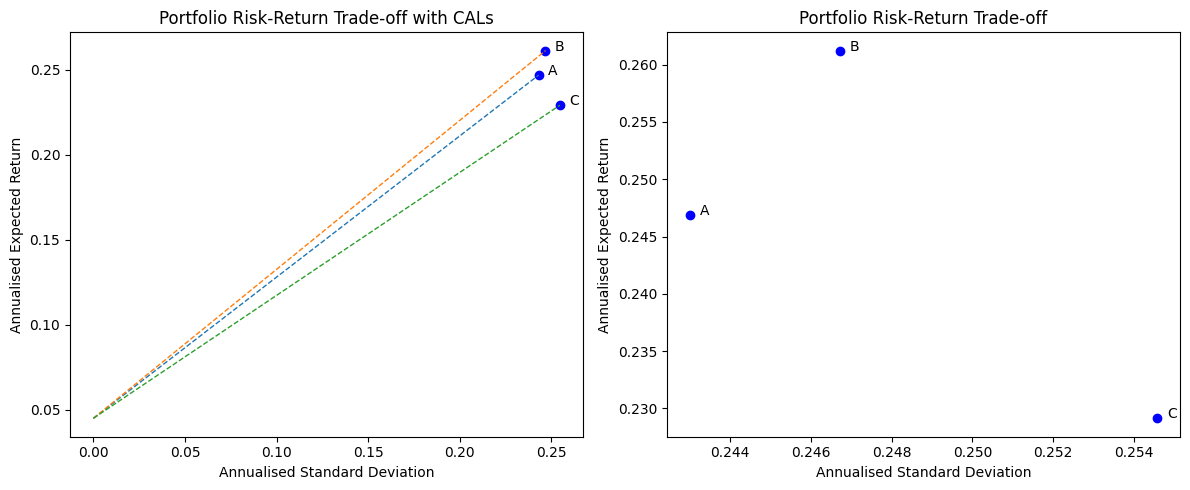

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax1, ax2 = axes

# Left Plot: Scatter Plot + CAL lines
ax1.scatter(std_annual, mean_annual, c="blue")

# Annotate each portfolio
for i, label in enumerate(mean_annual.index):
    x = float(std_annual.iloc[i])
    y = float(mean_annual.iloc[i])
    ax1.text(x + 0.005, y, label)
    
    # Draw CAL from last annualised risk-free rate to each portfolio
    ax1.plot([0, x], [rf_annual.iloc[-1], y], linestyle="--", linewidth=1)

ax1.set_xlabel("Annualised Standard Deviation")
ax1.set_ylabel("Annualised Expected Return")
ax1.set_title("Portfolio Risk-Return Trade-off with CALs")

# Right Plot: Scatter Plot 
ax2.scatter(std_annual, mean_annual, c="blue")

# Annotate each portfolio
for i, label in enumerate(mean_annual.index):
    x = float(std_annual.iloc[i])
    y = float(mean_annual.iloc[i])
    ax2.text(x + 0.00025, y, label)

ax2.set_xlabel("Annualised Standard Deviation")
ax2.set_ylabel("Annualised Expected Return")
ax2.set_title("Portfolio Risk-Return Trade-off")

plt.tight_layout()
plt.show()


From the plots it is clear that Portfolio B, which sits towards the top-left has a relatively low annual volatility of 0.2467 with the highest expected annual excess return of 0.2612, which explains its leading Sharpe ratio.

Portfolio A, with volatility 0.2430 and expected excess return 0.2469, lies slightly below B, but further left reflecting its lower risk and moderate performance.

Portfolio C shows the lowest expected excess return of 0.2291 and the highest volatility of 0.2546, making it the least efficient portfolio.

The CAL slopes in the left-hand plot show how each portfolio performs relative to the risk-free asset. A steeper slope corresponds to a higher Sharpe ratio with Portfolio B standing out as the most efficient portfolio on a risk-adjusted basis.

## Part C: Optimal Risky Portfolio

The optimal risky portfolio offers:

- Expected excess return: $E[R_P] - r_f = 10\% = 0.10$
- Variance: $\sigma_P^2 = 30\% = 0.30$

Each investor has a mean-variance utility function in the form: $$U = E(r) - A \, \text{Var}(r)$$ where $A$ represents their risk-aversion coefficient, applied directly to the full variance term rather than to $\frac{A}{2}$ (Imperial College Business School, 2024-25).

The optimal proportion of wealth invested in the risky portfolio is therefore given by:
$$y^* = \frac{E[R_P] - r_f}{2A \, \sigma_P^2}$$

The optimal allocations for each investor before accounting for any borrowing spread are calculated as follows:

In [52]:
excess_return = 0.10
variance = 0.30

#  Investor risk aversion coefficients (A)
risk_aversion = {
    "X": 1,
    "Y": 2,
    "Z": 0.1,
}

# Compute optimal proportion in risky portfolio
y_star = {name: excess_return / (2 * A * variance) for name, A in risk_aversion.items()}

allocations = pd.DataFrame.from_dict(y_star, orient="index", columns=["y* (Fraction in Risky Portfolio)"])
allocations["% in Risky"] = allocations["y* (Fraction in Risky Portfolio)"] * 100
allocations["% in Risk-Free"] = (1 - allocations["y* (Fraction in Risky Portfolio)"]) * 100

allocations.round(2)

,y* (Fraction in Risky Portfolio),% in Risky,% in Risk-Free
X,0.17,16.67,83.33
Y,0.08,8.33,91.67
Z,1.67,166.67,-66.67


We can see that Investor Z’s initial optimal allocation is 166.7% in the risky portfolio, which requires borrowing (a leveraged position). When an investor borrows to hold more than 100% in the risky portfolio, they must borrow at a higher interest rate. In this case, their effective risk-free rate becomes $r_f + 0.02$. Recomputing with the adjusted rate for investor Z gives:

In [53]:
# Adjust excess return for investor Z with 2% borrowing spread
adjusted_excess = {"X": excess_return, "Y": excess_return, "Z": excess_return - 0.02}

# Recompute optimal proportion in risky portfolio
y_star = { name: adj_excess / (2 * A * variance) for name, (A, adj_excess) in zip(risk_aversion.keys(), zip(risk_aversion.values(), adjusted_excess.values()))}

allocations = pd.DataFrame.from_dict(y_star, orient="index", columns=["y* (Fraction in Risky Portfolio)"])
allocations["% in Risky"] = allocations["y* (Fraction in Risky Portfolio)"] * 100
allocations["% in Risk-Free"] = (1 - allocations["y* (Fraction in Risky Portfolio)"]) * 100
allocations.round(2)

,y* (Fraction in Risky Portfolio),% in Risky,% in Risk-Free
X,0.17,16.67,83.33
Y,0.08,8.33,91.67
Z,1.33,133.33,-33.33


This means that:

- Investor X with moderate risk aversion, allocates one-sixth (16.7%) of total wealth to the risky portfolio.
- Investor Y being more risk-averse, invests one-twelfth (8.3%).
- Investor Z, with very low risk aversion, borrows at the risk-free rate to take a leveraged position exceeding 100% of wealth in the risky portfolio (133.3%).
   
The higher the risk-aversion coefficient $A$, the smaller the allocation to the risky portfolio. Accounting for the 2% borrowing spread reduces investor Z’s optimal exposure from 166.7% to 133.3%, as the higher borrowing cost makes leverage less attractive.

These results show that as risk aversion increases, the optimal exposure to the risky portfolio decreases, consistent with standard mean-variance preferences.

### CAL and Investor Utility Curves

This can be further visualised using the Capital Allocation Line (CAL) which shows how each investor’s utility-maximising allocation corresponds to different points along the risk-return trade-off curve.

The risk-free rate used is the annualised most recent one (4.5%). The line is slightly kinked at y=1 to account for the assumed 2% annualised borrowing spread for leveraged positions. This is particularly relevant for investor Z who borrows to invest more than 100% in the risky portfolio.

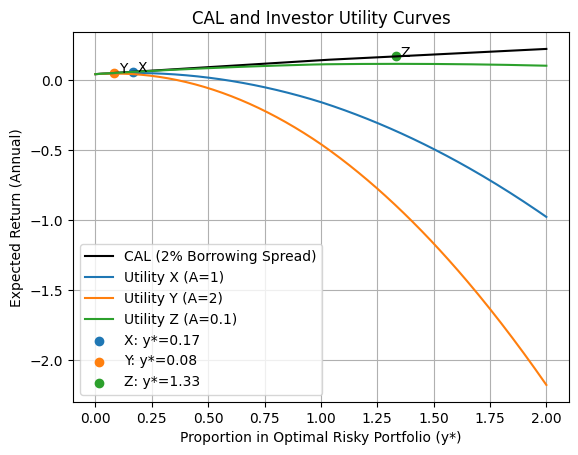

In [54]:
# Retrieve last annual risk-free rate and standard deviation
rf_last = rf_annual.iloc[-1]
sigma = np.sqrt(variance)

# Range of allocations to the risky portfolio from 0% to 200%
y = np.linspace(0, 2, 200)

# CAL with 2% borrowing spread for y > 1
cal = np.where(
    y <= 1,
    rf_last + y * excess_return,
    rf_last + 1 * excess_return + (y - 1) * 0.08
)

# Utility curves for each investor
utilities = {
    name: cal - A * (y**2) * variance for name, A in risk_aversion.items()
}

# PLot CAL and utility curves
plt.figure()
plt.plot(y, cal, label="CAL (2% Borrowing Spread)", color="black")
plt.plot(y, utilities["X"], label="Utility X (A=1)")
plt.plot(y, utilities["Y"], label="Utility Y (A=2)")
plt.plot(y, utilities["Z"], label="Utility Z (A=0.1)")

# Mark optimal allocations y* for each investor
for name, y_opt in y_star.items():
    ret_opt = np.interp(y_opt, y, cal)
    plt.scatter(y_opt, ret_opt, label=f"{name}: y*={y_opt:.2f}")
    plt.text(y_opt + 0.02, ret_opt, name)

plt.xlabel("Proportion in Optimal Risky Portfolio (y*)")
plt.ylabel("Expected Return (Annual)")
plt.title("CAL and Investor Utility Curves")
plt.legend()
plt.grid(True)
plt.show()


This plot shows the trade-off between risk and expected return, with a kink at $y = 1$ caused by the 2% borrowing spread for leveraged positions ($y > 1$). The utility curves illustrate how each investor’s optimal allocation depends on their risk aversion.

- Investor X $(A=1)$: X’s utility curve is moderately concave, so their optimal point occurs before the kink of the CAL at approximately 16.7% allocation to the risky portfolio.
- Investor Y $(A=2)$: Y is the most risk-averse, and their utility curve bends sharply downward. Their optimum lies very close to the risk-free rate at around 8.3% allocation to the risky portfolio.
- Investor Z $(A=0.1)$: Z’s utility curve is the flattest, so their optimum lies beyond the kinked point of the CAL even after the borrowing spread with an optimal allocation of 133.3%. 

## Part D: Single-Factor Arbitrage Pricing Theory (APT) Expected Excess Return Estimation

### Market Index Months Returns

From Lecture 2 (Imperial College Business School, 2024-25), under the single factor APT model, the expected return of a stock is given by:
$$R_i = E(R_i) + \beta_i F + e_i$$

where:

- $R_i$ is the excess return on stock $i$ 
- $F$ is the realisation of the single common factor
- $\beta_i$ is the factor loading (sensitivity) of stock $i$ 
- $e_i$ is the idiosyncratic component with $E[e_i] = 0$

Consistent with the single-factor APT model, we assume that monthly excess returns on each stock are explained by exposure to the market excess return which is based on the level of the S&P 500 index and the risk-free rate. The model therefore becomes:

$$(r_{i,t} - r_{f,t}) = \alpha_i + \beta_i (r_{M,t} - r_{f,t}) + \varepsilon_{i,t}$$

The first step in calculating the expected excess returns is therefore calculating the market returns from the `Market Index` sheet the same way we calculated the stock returns in part A.

In [55]:
market = pd.read_excel(xls, sheet_name="Market Index", index_col=0, parse_dates=True).dropna()

market_returns = market.pct_change().dropna()
market_returns.round(5).head()

,Level of the S&P 500 Index
Date,
2019-02-01,0.02973
2019-03-01,0.01792
2019-04-01,0.03931
2019-05-01,-0.06578
2019-06-01,0.06893


### Expected Market Excess Return

Now we can align the monthly stock returns, market returns, and risk-free rates by reindexing them to share the same dates and dropping any rows with missing data.

Then, we can compute the monthly market excess returns by subtracting the aligned risk-free rates from the aligned market returns:

$$r_{M,t}^{excess} = r_{M,t}-r_{f,t}$$

and estimate the expected excess return of the market for the next month as the historical mean of market excess returns:

$$
E[r_{M}^{excess}]=\overline{r_{M}^{excess}}
$$

In [56]:
# Align monthly returns, market returns, and risk-free rates
stocks_aligned = monthly_returns.reindex(market_returns.index).dropna()
market_aligned = market_returns.reindex(stocks_aligned.index).squeeze()

rf_aligned, market_aligned = rf_aligned.align(market_aligned, join="inner")
rf_aligned, stocks_aligned = rf_aligned.align(stocks_aligned, join="inner")

# Calculate market excess returns
market_excess = market_aligned.squeeze() - rf_aligned

# Calculate expected market excess return
expected_market_excess = market_excess.mean()
expected_market_excess.round(5)

0.01022

### Stock Betas

Given the expected market excess return of 1.022%, we now estimate each stock’s beta with respect to the market. Beta measures the sensitivity of a stock’s excess returns to movements in the market’s excess returns and is defined as:

$$\beta_i = \frac{\text{Cov}(R_i - r_f,R_M - r_f)}{\text{Var}(R_M - r_f)}$$

This is numerically equivalent to the slope coefficient obtained when regressing each stock’s excess returns on the market’s excess returns. 

Using the aligned excess return series, we compute the covariance between each stock excess returns and the market excess returns, divide by the variance of market excess returns, and obtain the betas shown below.

In [57]:
# Calculate excess returns for stocks
stocks_excess = stocks_aligned.sub(rf_aligned, axis=0)
market_excess_aligned = market_excess.reindex(stocks_excess.index)

# Calculate betas for each stock
betas = {}
for col in stocks_excess.columns:
    cov = stocks_excess[col].cov(market_excess_aligned)
    var = market_excess_aligned.var()
    betas[col] = cov / var
    
betas_df = pd.DataFrame.from_dict(betas, orient="index", columns=["Beta"]).round(3)
betas_df

,Beta
AAPL,1.265
AMZN,1.136
GE,1.227


### Stock Expected Excess Returns

Using the estimated betas below:

- AAPL: $\beta_{AAPL} = 1.265$
- AMZN: $\beta_{AMZN} = 1.136$
- GE: $\beta_{GE} = 1.227$

and the expected market excess return of 1.022%, we can finally compute the expected returns of the three stocks under the single-factor APT model. Since we assume a one-factor structure with no pricing errors $(\alpha_i= 0)$, the expected return on each stock for next month is given by:

$$E[R_i] = r_f^{next} + \beta_i E[r_M - r_f]^{next}$$

where $r_f^{next}$ is assumed as the most recent available monthly risk-free rate (0.375%).

In [58]:
# Estimate next month risk-free rate
rf_next = rf_aligned.iloc[-1]

# Calculate expected returns for each stock
expected_stock_returns = {
    name: rf_next + beta * expected_market_excess for name, beta in betas.items()
}

expected_df = pd.DataFrame.from_dict(expected_stock_returns, orient="index", columns=["Expected Return"])
expected_df.round(5)

,Expected Return
AAPL,0.01668
AMZN,0.01536
GE,0.01629


To summarise, the single-factor APT estimates produce expected monthly returns of 1.668% for AAPL, 1.536% for AMZN, and 1.629% for GE.

- AAPL showed the highest expected return, consistent with its highest beta of 1.265, meaning it is most sensitive to market movements.
- AMZN had the lowest beta of the three at 1.136 and therefore had the lowest expected return under the model.
- GE, despite not being a high-growth technology stock, had a beta comparable to AAPL’s and therefore received a similarly high expected return of 1.629%.

Importantly, all three stocks have expected returns above the risk-free rate next month (0.375%), consistent with the APT for assets with betas greater than one. The relative magnitudes are driven entirely by systematic risk exposure rather than firm-specific characteristics, since the no-alpha version of the model is used.

These results therefore illustrate a key implication of single-factor pricing models, that a higher exposure to market risk is compensated with higher expected return, and stocks with similar betas, regardless of sector, receive similar required returns.

### Ordinary Least Squares (OLS) Regression Validation

We can also dive deeper by comparing alpha and beta estimates from the Ordinary Least Squares (OLS) regressions to those computed via covariance and variance formulas. This helps validate our beta estimates and check for any pricing errors (non-zero alphas) in the single-factor APT model.

This is achieved through use of the `statsmodels` library to run the regressions of each stock’s excess returns on the market excess returns. The summary table below shows the estimated alphas and betas from the regressions alongside those computed via covariance and variance and the t-statistics for the alpha estimates.

In [ ]:
import statsmodels.api as sm

# Initialise dictionaries to store results
alphas = {}
ols_betas = {}
t_alpha = {}

# Run OLS regression for each stock
for col in stocks_excess.columns:
    X = sm.add_constant(market_excess_aligned) 
    y = stocks_excess[col]
    model = sm.OLS(y, X).fit()
    
    alphas[col] = model.params["const"]
    ols_betas[col] = model.params.iloc[1]
    t_alpha[col] = model.tvalues["const"]

# Create summary DataFrame
alpha_beta_df = pd.DataFrame({
    "Alpha": alphas,
    "OLS Beta": ols_betas,
    "Formula Beta": betas,
    "t-statistic (Alpha)": t_alpha,
}).round(5)

alpha_beta_df

,Alpha,OLS Beta,Formula Beta,t-statistic (Alpha)
AAPL,0.01392,1.26531,1.26531,2.15607
AMZN,0.00351,1.13617,1.13617,0.41599
GE,0.00116,1.22747,1.22747,0.10923


From this validation, it is evident that the the OLS betas match the formula betas almost exactly for all three stocks, confirming that the covariance-based implementation is correct.

Furthermore, the alpha estimates and t-statistics for the three stocks are very close to zero with the exception of AAPL which has an alpha of 1.39% and a t-statistic of 2.16, which is borderline statistically significant at the 5% level. The AAPL result suggests that, within this sample window, AAPL delivered excess performance not fully captured by the market factor alone.

Overall, despite AAPL’s borderline significance, the small magnitude and insignificance of the remaining alphas suggests that the single-factor APT model adequately explains the excess returns of these stocks without significant pricing errors.

### Stock Excess Returns vs Market Excess Returns

Now, we can visualise the relationship between each stock’s excess returns and the market excess return by plotting scatter plots with fitted regression lines and showing the equations.

Under the single-factor APT model, this relationship should be approximately linear, with the slope equal to the stock’s beta and the intercept equal to its alpha. Plotting the scatter of $r_{i,t}^{\text{excess}}$ against $r_{M,t}^{\text{excess}}$, together with the fitted regression line, allows us to verify the sign and magnitude of each beta and visually confirm whether the single-factor model provides a reasonable fit for the data.

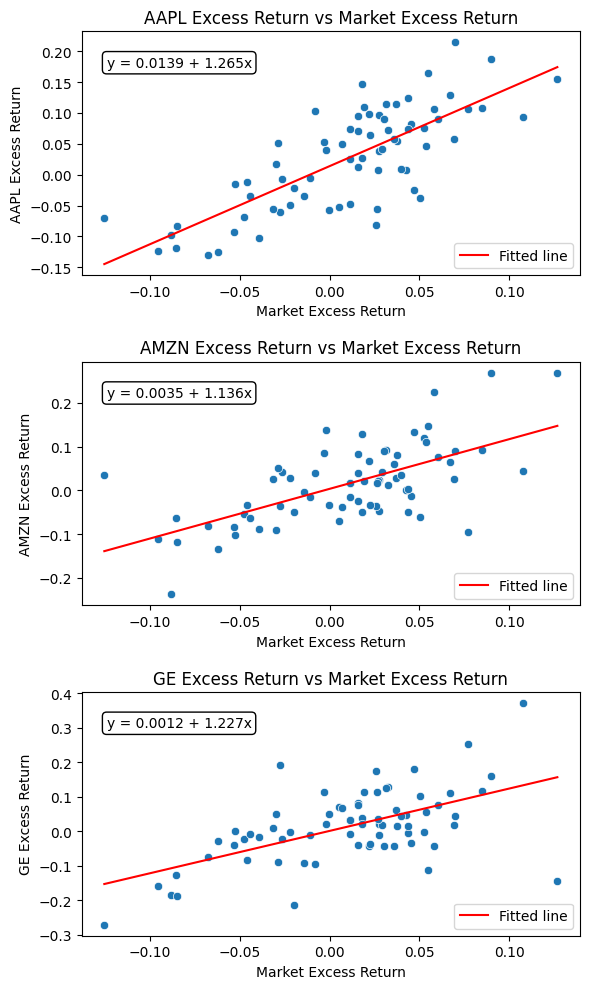

In [68]:
fig, axes = plt.subplots(3, 1, figsize=(6, 10))

# Generate x values for fitted line
x_line = np.linspace(market_excess_aligned.min(), market_excess_aligned.max(), 100)

# Plot for each stock
for i, stock in enumerate(stocks_excess.columns):
    ax = axes[i]
    
    # Scatter Plot
    sns.scatterplot(
        x=market_excess_aligned,
        y=stocks_excess[stock],
        ax=ax
    )
    # Get estimated alpha and calculated beta
    alpha = alpha_beta_df.loc[stock, "Alpha"]

    # Use betas from calculated covariance/variance formula
    beta = betas[stock] 

    # Fitted line using betas
    y_line = alpha + beta * x_line
    ax.plot(x_line, y_line, color="red", label="Fitted line")

    ax.set_title(f"{stock} Excess Return vs Market Excess Return")
    ax.set_xlabel("Market Excess Return")
    ax.set_ylabel(f"{stock} Excess Return")
    
    # Show equation
    ax.text(
        0.05, 0.9,
        f"y = {alpha:.4f} + {beta:.3f}x",
        transform=ax.transAxes,
        ha="left",
        va="top",
        bbox=dict(boxstyle="round", facecolor="white")
    )
    
    ax.legend()

plt.tight_layout(h_pad=1.5)
plt.show()

Overall, the fitted lines confirm the strong positive relationship between each stock’s excess returns and the market excess return, consistent with the single-factor APT framework. All three stocks exhibit betas greater than one, meaning they are more sensitive to market movements than the market itself. AAPL has the steepest slope $(\beta = 1.27)$, followed by GE $(\beta = 1.23)$ and AMZN $(\beta = 1.14)$, which matches the relative steepness seen in the scatterplots.

The intercept terms (alphas) in the regression lines are close to zero for AMZN and GE, indicating little evidence of systematic mispricing, whereas AAPL shows a small positive alpha, but not large enough to meaningfully contradict the single-factor model.

Taken together, the results suggest that the market factor explains the majority of variation in monthly excess returns for all three stocks, and the beta estimates obtained from both covariance formulas and OLS regressions are visually and numerically consistent. This validates the expected-return estimates derived earlier and indicates that the single-factor APT provides a reasonable description of these stocks’ historical behaviour.

## Part E: Additional Factor - Profitability

In addition to the market factor used in the single-factor APT model, multi-factor extensions can incorporate additional systematic risk factors that capture other dimensions of expected returns.

Under the multi-factor APT expected returns can be expressed as:

$$ 
E[R_i] = R_f + \beta_{iM}E[R_M - R_f] + \sum_{k=2}^{K} \beta_{ik}E[F_k]
$$ 

where each additional $F_k$ represents a priced source of systematic risk. 

From Fama and French (1993), the original three factor model included market, size, and value factors. Their later work introduced two additional factors, namely the Profitability factor (RMW) and Investment factor (CMA), as part of their five-factor model (Fama and French, 2015). In this part we will explore the significance of the Profitability factor, commonly called the Robust Minus Weak (RMW) factor and described as the difference in returns on diversified stock portfolios with strong versus weak profitability (Bodie, Kane and Marcus, 2021).

From Table 4, Panel A, in Fama and French's "A five-factor asset pricing model" (2015), the RMW factor constructed using the standard $2 \times 3$ (size $\times$ profitability) sorting can be seen to exhibit a t-statistic of 2.92 and a positive average monthly return of 0.25%, indicating statistical significance at the 5% level. However, under the alternative $2 \times 2 \times 2 \times 2$ sorting (size, profitability, investment, and value), the RMW delivers a higher t-statistic of 4.09 for the same average monthly return, reflecting stronger statistical significance.

Additionally, Jonathan Lewellen (2014) provides further evidence on the role of the Profitability factor by examining return forecasts constructed from firm-level accounting variables, with Return on Assets (ROA) serving as his primary profitability measure. He finds that firms with higher ROA consistently earn higher expected and realised returns, with the ROA characteristic displaying a strong positive slope of 1.43 and a t-statistic of 3.57, satisfying the threshold of $t > 3$ recommended by Harvey, Liu & Zhu (2016). This supports the idea that profitability-based factors such as ROA and RMW make Profitability a statistically and economically meaningful addition to the APT framework, since they capture the premium associated with strong operating performance (Lewellen, 2014).

### Economic Rationale:   
Essentially, more profitable firms tend to have persistent earnings, stronger balance sheets, and lower financial distress risk, making them load positively on the RMW factor, which earns a positive premium. Conversely, less profitable firms must offer higher expected returns to compensate for the greater default or operational risk.

### Construction: 
A long-short portfolio formed by going long high-ROA firms and short low-ROA firms, rebalanced monthly, generates the Profitability factor. Its mean excess return subsequently captures the premium associated with exposure to profitability.

### Statistical Justification: 
Harvey, Liu, and Zhu (2016) emphasise the “factor zoo” problem, showing that out of 296 documented anomalies, 27% to 53% are likely false discoveries once multiple-testing adjustments are applied. Therefore, they propose a threshold of $t>3$ for newly introduced factors to be considered credible (Harvey, Liu and Zhu, 2016).

Further evidence of the factor-zoo problem comes from Hou, Xue, and Zhang (2020), who examined 452 anomalies and found that 82% of them become insignificant once microcap stocks are excluded and value-weighted returns are used. These findings highlight that the majority of proposed factors lack robustness, reinforcing the need to focus on a much smaller set of economically motivated and empirically persistent factors (Hou, Xue and Zhang, 2020).

Therefore, Profitability stands out as one of the few factors whose predictive power remains statistically significant after applying the stricter standards motivated by the factor-zoo literature.Lewellen's ROA factor with a t-statistic of 3.57 meets this stricter criterion but Fama and French's standard $2 \times 3$ RMW t-statistic of 2.92 falls just below this threshold. However, its economic motivation, empirical robustness, and consistent performance across samples mean that Profitability should be among the small number of factors considered empirically reliable. Moreover, the alternative $2 \times 2 \times 2 \times 2$ construction exceeds the $t>3$ benchmark, demonstrating stronger statistical power under a finer portfolio construction. 

## Part F: Predictive Power of the Profitability Factor

Building on the significance of the Profitability factor (RMW) established in Part E, we now examine how it incorporating it into a two-factor model would affect the expected excess returns of AAPL, AMZN, and GE.

Since RMW reflects the return premium earned by firms with strong operating performance relative to those with weak profitability, portfolios sorted on profitability exhibit persistent differences in returns, even after controlling for market, size, and value effects (Fama and French, 2015). This behaviour suggests that profitability captures systematic risk exposures not accounted for by the single-factor APT/CAPM.

A rational, risk based explanation for the Profitability factor's significance is that firms with low profitability face greater sensitivity to adverse economic conditions, higher likelihood of financial distress risk and more volatile earnings streams. Therefore, investors demand additional compensation since these firms' cash flows are riskier.

On the other hand, highly profitable firms have more stable cash flows, stronger internal financing capacity, and a lower likelihood of financial distress risk, resulting in a lower required risk premium. Under this interpretation, the Profitability factor compensates investors for taking on systematic risk associated with firms' operating performance.

### Empirical Support
We have seen that the RMW factor produces a positive and statistically significant average monthly excess return with a positive average excess monthly return and a t-statistic of 2.92 under the standard $2 \times 3$ sorting and a t-statistic of 4.09 under the alternative $2 \times 2 \times 2 \times 2$ sorting (Fama and French, 2015) which meets the stricter criteria of $t>3$ proposed by Harvey, Liu and Zhu (2016) to avoid false discoveries in the factor zoo. These results indicate that the Profitability factor has strong and consistent predictive power across different portfolio construction methods.

### APT with Profitability Factor
Extending the single-factor APT to incorporate RMW, the expected returns under a two-factor model are given by:

$$ 
E[R_i] = R_f + \beta_{i,M}E[R_M - R_f] + \beta_{i,RMW}E[F_{RMW}]
$$ 

Here:

- $E[F_{RMW}]$ is the expected excess return of the Profitability factor. 
- $\beta_{i,RMW}$ measures a stock’s sensitivity to the Profitability factor.

### Interpretation
- Positive $\beta_{i,RMW}$: The stock benefits from exposure to the profitability premium, earning higher expected returns when profitability-related risks are rewarded.   
- Negative $\beta_{i,RMW}$: The stock lacks exposure to profitability so experiences lower expected returns.

### Application to AAPL, AMZN, and GE
The expected impact of adding the Profitability factor to the APT model for AAPL, AMZN, and GE can be inferred by examining each firm's performance and results from Part D such as expected excess returns and betas. Therefore, the profitability betas $\beta_{RMW}$ for each stock would likely be:

#### AAPL - Highest and Positive $\beta_{RMW}$:
- AAPL displayed the highest expected excess return of 1.668% under the single-factor APT and a beta of 1.265, showing strong market sensitivity. 
- Given AAPL's consistently high profitability and reputation as a high quality firm, it is reasonable to expect a strong positive exposure to the Profitability factor.
- Additionally, AAPL had the highest alpha and was the only stock with a borderline significant t-statistic estimate from the OLS regression which suggests that its returns were not fully captured by the market excess return alone which supports the idea that there are additional priced sources of risk such as profitability.

#### AMZN - Positive but Moderate $\beta_{RMW}$:
- AMZN exhibited a moderate beta of 1.136 and the lowest expected excess return of 1.536% under the single-factor APT.
- It also showcased a relatively small alpha compared to AAPL but higher than GE so AMZN likely has a positive but more moderate exposure to the Profitability factor.

#### GE - Low or Negative $\beta_{RMW}$:
- GE had a beta of 1.227 and an expected excess return of 1.629% under the single-factor APT.
- However, GE displayed the lowest alphas and the highest volatility from the plot of monthly returns and the covariance matrix in Part A, reflecting little unexplained return beyond market excess return exposure.
- Therefore, GE is likely to have a low or even negative exposure to the Profitability factor, as its weak operating performance would not benefit from the profitability premium.

In summary, the expected ordering of the profitability betas is:

$$\beta_{RMW,AAPL} > \beta_{RMW,AMZN} > \beta_{RMW,GE}$$

This is due to the observed empirical results showing that AAPL has the highest expected return and residual performance whilst GE has the weakest fundamentals and lowest unexplained returns after accounting for market exposure.

## References

Amazon.com, Inc. (2022). Investor Relations FAQ - Stock Split Information. Amazon Investor Relations.  
Available at: https://ir.aboutamazon.com/faqs/default.aspx  
(Accessed: 7 November 2025).

Apple Inc. (2020). Investor Relations FAQ - Stock Split Information. Apple Investor Relations.  
Available at: https://investor.apple.com/faq/default.aspx  
(Accessed: 7 November 2025). 

Bodie, Z., Kane, A. and Marcus, A.J. (2021). Investments. 12th ed. New York: McGraw-Hill Education.
ISBN 978-1-266-08596-3

Fama, E.F. and French, K.R. (1993). “Common Risk Factors in the Returns on Stocks and Bonds.” Journal of Financial Economics, 33(1), pp.3-56.  
https://doi.org/10.1016/0304-405X(93)90023-5

Fama, E.F. and French, K.R. (2015). A five-factor asset pricing model. Journal of Financial Economics, 116(1), pp.1-22. 
https://doi.org/10.1016/j.jfineco.2014.10.010

General Electric Company (2021). GE Reverse Stock Split FAQs. GE Investor Relations.  
Available at: https://www.ge.com/sites/default/files/GE_Reverse_Stock_Split_FAQs.pdf  
(Accessed: 7 November 2025).

Harvey, C.R., Liu, Y. and Zhu, H. (2016). “…and the Cross-Section of Expected Returns.” The Review of Financial Studies, 29(1), pp.5-68.  
https://doi.org/10.1093/rfs/hhv059

Hou, K., Xue, C. and Zhang, L. (2020). "Replicating Anomalies". The Review of Financial Studies, 33(5), pp. 2019-2133.
https://doi.org/10.1093/rfs/hhy131

Imperial College Business School (2024-25). Investment and Portfolio Management [Lecture slides and notes, Lectures 1-4]. London: Imperial College Business School.

Johansson, K., Ogut, M.G., Pelger, M., Schmelzer, T. and Boyd, S. (2023) A simple method for predicting covariance matrices of financial returns.
Available at: https://www-leland.stanford.edu/~boyd/papers/pdf/cov_pred_finance.pdf
(Accessed: 7 November 2025).

Lewellen, J.W. (2014). The Cross Section of Expected Stock Returns. Tuck School of Business Working Paper No. 2511246. Forthcoming in Critical Finance Review.  
https://dx.doi.org/10.2139/ssrn.2511246 